# BEP

# Pre-work

In [49]:
# imports

from pathlib import Path
import pandas as pd
import json
import ollama

from tqdm import tqdm

from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

In [50]:
# config

tqdm.pandas()

In [51]:
# constants

ROOT_DIR = Path.cwd().parent
DATASET_DIR = ROOT_DIR / "datasets"

NOVIELLI_GOLD_STANDARD_DIR = DATASET_DIR / "novielli-gh-gold"
GH_GOLD_STANDARD = NOVIELLI_GOLD_STANDARD_DIR / "github_gold.csv"

COUTINHO_DIR = DATASET_DIR / "coutinho-sentiment-replication"
COUTINHO = COUTINHO_DIR / "dataset.json"

DEVA_INPUT_DIR = ROOT_DIR / "input" / "deva"
DEVA_OUTPUT_DIR = ROOT_DIR / "output" / "deva"

### Data collection (Novielli et al., 2020)

The dataset used by Novieli et al. is in CSV format, which makes it straight forward to create dataframes out of it.

In [52]:
df_novielli = pd.read_csv(GH_GOLD_STANDARD, sep=';', quotechar='"', encoding='utf-8')
df_novielli.columns = df_novielli.columns.str.lower()

# strip outer quote
df_novielli['text'] = df_novielli['text'].str.rstrip('"')
df_novielli

,id,polarity,text
0,4063186,neutral,No. I still see the wrong twins. * https://gi...
1,3894703,neutral,Reverted.
2,1971084,neutral,You can leave a queue while in queue ? (before...
3,1827828,positive,Didn't look at SpellTargetRestrictions XD
4,232603,neutral,Not sure about what kind of line lengths the p...
...,...,...,...
7117,963856,negative,"Yeah, I'm capable of working around it. A set..."
7118,5074806,positive,"Looks fine to me! On Jul 8, 2013, at 10:12 PM..."
7119,6359700,positive,Formula updated to address this (would be nice...
7120,3832826,positive,I trust you


### Data collection (Coutinho et al., 2024)

Since this dataset is in nested JSON format, we do some extra pre-processing to normalize it.

In [53]:
text = COUTINHO.read_text(encoding="utf-8")

if text.lstrip().startswith("["):
    data = json.loads(text)
else:
    try:
        data = [json.loads(line) for line in text.splitlines() if line.strip()]
    except json.JSONDecodeError:
        data = [json.loads(text)]

df_coutinho = pd.json_normalize(data, sep="_")

df_coutinho['polarity'] = df_coutinho['part2_aggregate_polarity'].where(
    df_coutinho['part2_aggregate_polarity'] != 'undefined',
    other=df_coutinho['discussion_polarity']
)
df_coutinho = df_coutinho[df_coutinho['polarity'].notna() & (df_coutinho['polarity'] != 'undefined')]

In [54]:
print(df_coutinho.shape)
df_coutinho.head(5)

(1791, 13)


,raw_message,clean_message,message_url,part2_aggregate_polarity,part2_aggregate_avg_confidence,part2_aggregate_agreement_type,tools_SentiStrength,tools_SentiStrengthSE,tools_SentiCR,tools_DEVA,tools_Senti4SD,discussion_polarity,polarity
0,@snicoll did you get a chance to follow up on ...,did you get a chance to follow up on the issue...,https://github.com/spring-projects/spring-boot...,neutral,4.333333,neuro_and_comp,neutral,neutral,neutral,neutral,neutral,NaN,neutral
1,Thank you for this PR. This is an interesting...,Thank you for this PR. This is an interesting...,https://github.com/google/guice/pull/1349#issu...,undefined,4.666667,undefined,negative,negative,negative,negative,neutral,neutral,neutral
2,"@mbhave, oh sorry for this, my fault, i'll be...",", oh sorry for this, my fault, i'll be more c...",https://github.com/spring-projects/spring-boot...,negative,5.000000,all,negative,negative,neutral,negative,neutral,NaN,negative
3,I've added `merge-with-amendments` so that we ...,I've added so that we can add documentation r...,https://github.com/spring-projects/spring-boot...,neutral,4.000000,comp_only,neutral,neutral,neutral,neutral,neutral,NaN,neutral
4,> @Primary and @ConditionalOnMissingBean. I th...,Applications can still use or qualifiers to g...,https://github.com/spring-projects/spring-boot...,negative,4.666667,all,negative,negative,neutral,negative,negative,NaN,negative


# DEVA Experiments

## Running DEVA collected datasets

DEVA expects an input .txt file with the message to be analyzed and its ID. To demonstrate, this is the example input they provide with the tool:
```
58204 Yes, that's correct.
32957 Challenge accepted! :)
45982 No problem.  It was my pleasure, and thanks for all the help.
63699 Still need tests  Neutral
14350 My mistake, sorry
```

It outputs the original input, as well as three extra columns: its valence score, its arousal score, and an emotional state label derived from the combination of both.

For the purposes of this replication study, however, the benchmark reduces sentiment to a three-class polarity task (positive, negative, neutral), so only the valence score is used. This maps directly to Novielli et al. replication's $±[1,3]$ schema:
- valence > +1 -> positive
- valence < -1 -> negative
- valence = ± 1 -> neutral

The output for the example input looks as follows:
```
58204 Yes, that's correct.  -2  -3    DEPRESSED
32957 Challenge accepted! :)  2   5   EXCITED
45982 No problem.  It was my pleasure, and thanks for all the help.   4   3   EXCITED
63699 Still need tests  Neutral   1   -2    NEUTRAL (LA)
14350 My mistake, sorry   -2  1   NEG VALENCE
```

Therefore, to run DEVA on the datasets collected above, we need to generate valid input, and then parse the output into dataframes.

In [55]:
def write_deva_input(df, output_path, id_col='id', text_col='text'):
    """Write a DEVA-compatible input .txt file from a dataframe."""
    df_out = df[[id_col, text_col]].drop_duplicates(subset=id_col)
    df_out.to_csv(output_path, sep='\t', header=False, index=False)

In [56]:
# novielli: already has 'id' and 'text' columns
write_deva_input(df_novielli, DEVA_INPUT_DIR / "nov_gh.txt")

# coutinho: needs synthetic IDs and uses 'clean_message' as text
df_coutinho_input = df_coutinho[['clean_message']].copy()
df_coutinho_input.insert(0, 'id', range(len(df_coutinho_input)))
write_deva_input(df_coutinho_input, DEVA_INPUT_DIR / "cou.txt", text_col='clean_message')

In [57]:
def parse_deva_output(filepath, dataset_label):
    rows = []
    with open(filepath, 'r', encoding='utf-8') as f:
        for line in f:
            parts = line.rstrip('\n').rsplit('\t', 3)  # split from right: [id+text, valence, arousal, label]
            if len(parts) == 4:
                id_and_text, valence, arousal, label = parts
                id_, text = id_and_text.split('\t', 1)  # split id from text on first tab
                rows.append({
                    'id': id_.strip(),
                    'text': text.strip(),
                    'valence': int(valence.strip()),
                    'arousal': int(arousal.strip()),
                    'deva_label': label.strip(),
                    'dataset': dataset_label
                })
    return pd.DataFrame(rows)

In [58]:
df_deva_novielli = parse_deva_output(DEVA_OUTPUT_DIR / "nov_gh_out.txt", "novielli")
df_deva_novielli.head(5)

,id,text,valence,arousal,deva_label,dataset
0,4063186,No. I still see the wrong twins. * https://gi...,-2,-2,DEPRESSED,novielli
1,3894703,Reverted.,1,1,NEUTRAL,novielli
2,1971084,You can leave a queue while in queue ? (before...,1,-3,NEUTRAL (LA),novielli
3,1827828,Didn't look at SpellTargetRestrictions XD,1,-2,NEUTRAL (LA),novielli
4,232603,Not sure about what kind of line lengths the p...,4,-3,RELAXED,novielli


In [59]:
df_deva_coutinho = parse_deva_output(DEVA_OUTPUT_DIR / "cou_out.txt", "coutinho")
df_deva_coutinho.head(5)

,id,text,valence,arousal,deva_label,dataset
0,0,did you get a chance to follow up on the issue...,1,-2,NEUTRAL (LA),coutinho
1,1,"""Thank you for this PR. This is an interestin...",-3,-4,DEPRESSED,coutinho
2,2,", oh sorry for this, my fault, i'll be more c...",-2,-3,DEPRESSED,coutinho
3,3,I've added so that we can add documentation r...,1,-3,NEUTRAL (LA),coutinho
4,4,Applications can still use or qualifiers to g...,-2,-4,DEPRESSED,coutinho


## Mapping DEVA results to polarity labels

As mentioned above, the following mapping is used:
- valence > +1 -> positive
- valence < -1 -> negative
- valence = ± 1 -> neutral

In [60]:
def valence_to_polarity(v):
    if v > 1:
        return 'positive'
    elif v < -1:
        return 'negative'
    else:
        return 'neutral'

In [61]:
df_deva_novielli['deva_polarity'] = df_deva_novielli['valence'].apply(valence_to_polarity)
df_deva_novielli

,id,text,valence,arousal,deva_label,dataset,deva_polarity
0,4063186,No. I still see the wrong twins. * https://gi...,-2,-2,DEPRESSED,novielli,negative
1,3894703,Reverted.,1,1,NEUTRAL,novielli,neutral
2,1971084,You can leave a queue while in queue ? (before...,1,-3,NEUTRAL (LA),novielli,neutral
3,1827828,Didn't look at SpellTargetRestrictions XD,1,-2,NEUTRAL (LA),novielli,neutral
4,232603,Not sure about what kind of line lengths the p...,4,-3,RELAXED,novielli,positive
...,...,...,...,...,...,...,...
7117,963856,"""Yeah, I'm capable of working around it. A se...",-3,-3,DEPRESSED,novielli,negative
7118,5074806,"Looks fine to me! On Jul 8, 2013, at 10:12 PM...",4,5,EXCITED,novielli,positive
7119,6359700,Formula updated to address this (would be nice...,1,-3,NEUTRAL (LA),novielli,neutral
7120,3832826,I trust you,-2,-2,DEPRESSED,novielli,negative


In [62]:
df_deva_coutinho['deva_polarity'] = df_deva_coutinho['valence'].apply(valence_to_polarity)
df_deva_coutinho

,id,text,valence,arousal,deva_label,dataset,deva_polarity
0,0,did you get a chance to follow up on the issue...,1,-2,NEUTRAL (LA),coutinho,neutral
1,1,"""Thank you for this PR. This is an interestin...",-3,-4,DEPRESSED,coutinho,negative
2,2,", oh sorry for this, my fault, i'll be more c...",-2,-3,DEPRESSED,coutinho,negative
3,3,I've added so that we can add documentation r...,1,-3,NEUTRAL (LA),coutinho,neutral
4,4,Applications can still use or qualifiers to g...,-2,-4,DEPRESSED,coutinho,negative
...,...,...,...,...,...,...,...
1786,1786,"Hmm, looks like r737027 corresponds to version...",1,-3,NEUTRAL (LA),coutinho,neutral
1787,1787,"<!-- First of all, thank you for your contribu...",-2,5,STRESSED,coutinho,negative
1788,1788,"there was a typo in the comment, also made a s...",1,-3,NEUTRAL (LA),coutinho,neutral
1789,1789,Fixed some typos. Added the ghost button type....,-2,-4,DEPRESSED,coutinho,negative


## Comparing resulting DEVA labels to original labels

In [63]:
def merge_with_gold(df_pred, df_gold, id_type=None):
    """Merge DEVA predictions with gold-standard labels on 'id'."""
    df = df_pred.copy()
    if id_type is not None:
        df['id'] = df['id'].astype(id_type)
    return df.merge(df_gold[['id', 'polarity']], on='id')

In [64]:
# novielli: gold IDs are ints, DEVA output IDs are strings
df_merged_novielli = merge_with_gold(df_deva_novielli, df_novielli, id_type=int)
df_merged_novielli

,id,text,valence,arousal,deva_label,dataset,deva_polarity,polarity
0,4063186,No. I still see the wrong twins. * https://gi...,-2,-2,DEPRESSED,novielli,negative,neutral
1,3894703,Reverted.,1,1,NEUTRAL,novielli,neutral,neutral
2,1971084,You can leave a queue while in queue ? (before...,1,-3,NEUTRAL (LA),novielli,neutral,neutral
3,1827828,Didn't look at SpellTargetRestrictions XD,1,-2,NEUTRAL (LA),novielli,neutral,positive
4,232603,Not sure about what kind of line lengths the p...,4,-3,RELAXED,novielli,positive,neutral
...,...,...,...,...,...,...,...,...
7117,963856,"""Yeah, I'm capable of working around it. A se...",-3,-3,DEPRESSED,novielli,negative,negative
7118,5074806,"Looks fine to me! On Jul 8, 2013, at 10:12 PM...",4,5,EXCITED,novielli,positive,positive
7119,6359700,Formula updated to address this (would be nice...,1,-3,NEUTRAL (LA),novielli,neutral,positive
7120,3832826,I trust you,-2,-2,DEPRESSED,novielli,negative,positive


In [65]:
# coutinho: build gold labels with synthetic IDs matching DEVA input
df_coutinho_labels = df_coutinho[['polarity']].copy()
df_coutinho_labels.insert(0, 'id', df_coutinho_labels.index.astype(str))
df_coutinho_labels = df_coutinho_labels[df_coutinho_labels['polarity'].notna() & (df_coutinho_labels['polarity'] != 'undefined')]

df_merged_coutinho = merge_with_gold(df_deva_coutinho, df_coutinho_labels)
df_merged_coutinho

,id,text,valence,arousal,deva_label,dataset,deva_polarity,polarity
0,0,did you get a chance to follow up on the issue...,1,-2,NEUTRAL (LA),coutinho,neutral,neutral
1,1,"""Thank you for this PR. This is an interestin...",-3,-4,DEPRESSED,coutinho,negative,neutral
2,2,", oh sorry for this, my fault, i'll be more c...",-2,-3,DEPRESSED,coutinho,negative,negative
3,3,I've added so that we can add documentation r...,1,-3,NEUTRAL (LA),coutinho,neutral,neutral
4,4,Applications can still use or qualifiers to g...,-2,-4,DEPRESSED,coutinho,negative,negative
...,...,...,...,...,...,...,...,...
1786,1786,"Hmm, looks like r737027 corresponds to version...",1,-3,NEUTRAL (LA),coutinho,neutral,negative
1787,1787,"<!-- First of all, thank you for your contribu...",-2,5,STRESSED,coutinho,negative,neutral
1788,1788,"there was a typo in the comment, also made a s...",1,-3,NEUTRAL (LA),coutinho,neutral,neutral
1789,1789,Fixed some typos. Added the ghost button type....,-2,-4,DEPRESSED,coutinho,negative,neutral


### Calculating precision, recall, F1 for DEVA results

For each class $cls$ of $classes=[positive, negative, neutral]$, we compute:
$$\text{precision}(cls) = \frac{TP}{TP + FP}\;\;\;\;\;\;\;\;\text{(of all messages predicted as class cls, the fraction that are truly cls)}$$
$$\text{recall}(cls) = \frac{TP}{TP + FN}\;\;\;\;\;\;\;\;\text{(of all messages that are truly of class cls, the fraction correctly identified)}$$
$$\text{f1}(cls) = 2\times\frac{\text{precision}(cls) \times \text{recall}(cls)}{\text{precision}(cls) + \text{recall}(cls)}\;\;\;\;\;\;\;\;\text{(harmonic mean of precision and recall)},$$
where for each class $cls$, TP is the number of messages correctly predicted as $cls$, FP is the number of messages incorrectly predicted as $cls$, and FN is the number of messages that belong to $cls$ but were predicted as a different class.

Moreover, for each metric, we compute macro averages and weighted averages:
$$\text{precision}_{\text{macro}} = \frac{1}{|classses|}\sum_{cls}\text{precision}(cls)$$
$$\text{precision}_{\text{weighted}} = \frac{\sum_{cls}\text{precision}(cls)\times|cls|}{\sum_{cls}|cls|}$$

We also aggregate TP, FP, FN across all classes to calculate an overall accuracy: micro-average. We use the following formulae:

$$\text{precision}_\text{micro}=\frac{\sum_{cls}TP_{cls}}{\sum_{cls}(TP_{cls}+FP_{cls}}$$
$$\text{recall}_\text{micro}=\frac{\sum_{cls}TP_{cls}}{\sum_{cls}(TP_{cls}+FN_{cls})}$$
$$\text{f1}_\text{micro}=2\times\frac{\text{precision}_\text{micro}\times \text{recall}_\text{micro}}{\text{precision}_\text{micro}+ \text{recall}_\text{micro}}$$

Note that in a multiclass setting where every sample gets exactly one label (as is in our case), $\sum TP_{cls} = \sum(TP_{cls} + FP_{cls}) = \sum(TP_{cls} + FN_{cls})$ (total number of samples). Therefore, $\text{precision}_\text{micro} = \text{recall}_\text{micro} = \text{f1}_\text{micro}$, which serves as an overall accuracy.

In [66]:
def compute_metrics(df, dataset_name, pred_col='deva_polarity', gold_col='polarity'):
    classes = ['positive', 'negative', 'neutral']
    rows = []

    for cls in classes:
        tp = ((df[pred_col] == cls) & (df[gold_col] == cls)).sum()
        fp = ((df[pred_col] == cls) & (df[gold_col] != cls)).sum()
        fn = ((df[pred_col] != cls) & (df[gold_col] == cls)).sum()
        
        precision = tp / (tp + fp) if (tp + fp) > 0 else 0
        recall    = tp / (tp + fn) if (tp + fn) > 0 else 0
        f1        = 2 * precision * recall / (precision + recall) if (precision + recall) > 0 else 0
        
        rows.append({
            'dataset': dataset_name,
            'class': cls,
            'precision': precision,
            'recall': recall,
            'f1': f1,
            'support': (df[gold_col] == cls).sum()
        })


    # macro average (simple mean across classes, like Coutinho et al.)
    macro = pd.DataFrame(rows)
    rows.append({
        'dataset': dataset_name,
        'class': 'macro avg',
        'precision': macro['precision'].mean(),
        'recall': macro['recall'].mean(),
        'f1': macro['f1'].mean(),
        'support': len(df)
    })

    # weighted average (mean weighted by class support)
    total = len(df)
    rows.append({
        'dataset': dataset_name,
        'class': 'weighted avg',
        'precision': (macro['precision'] * macro['support']).sum() / total,
        'recall':    (macro['recall']    * macro['support']).sum() / total,
        'f1':        (macro['f1']        * macro['support']).sum() / total,
        'support': total
    })

    # micro average (aggregate TP/FP/FN across all classes first)
    tp_sum = sum(((df[pred_col] == c) & (df[gold_col] == c)).sum() for c in classes)
    fp_sum = sum(((df[pred_col] == c) & (df[gold_col] != c)).sum() for c in classes)
    fn_sum = sum(((df[pred_col] != c) & (df[gold_col] == c)).sum() for c in classes)
    micro_p = tp_sum / (tp_sum + fp_sum) if (tp_sum + fp_sum) > 0 else 0
    micro_r = tp_sum / (tp_sum + fn_sum) if (tp_sum + fn_sum) > 0 else 0
    micro_f = 2 * micro_p * micro_r / (micro_p + micro_r) if (micro_p + micro_r) > 0 else 0
    rows.append({
        'dataset': dataset_name,
        'class': 'micro avg',
        'precision': micro_p,
        'recall': micro_r,
        'f1': micro_f,
        'support': total
    })


    return pd.DataFrame(rows)

In [67]:
metrics_novielli  = compute_metrics(df_merged_novielli,  'novielli')
metrics_coutinho  = compute_metrics(df_merged_coutinho, 'coutinho')

metrics_all = pd.concat([metrics_novielli, metrics_coutinho], ignore_index=True)
metrics_all

,dataset,class,precision,recall,f1,support
0,novielli,positive,0.702437,0.744660,0.722932,2013
1,novielli,negative,0.654648,0.722089,0.686717,2087
2,novielli,neutral,0.814222,0.723693,0.766293,3022
3,novielli,macro avg,0.723769,0.730147,0.725314,7122
4,novielli,weighted avg,0.735866,0.729149,0.730719,7122
5,novielli,micro avg,0.729149,0.729149,0.729149,7122
6,coutinho,positive,0.664903,0.723608,0.693015,521
7,coutinho,negative,0.484076,0.703704,0.573585,432
8,coutinho,neutral,0.798658,0.568019,0.663877,838
9,coutinho,macro avg,0.649212,0.665110,0.643492,1791


Note: the weighted average in the results is higher than the macro average mostly because the model seems to do much better on neutral text.

Note: the numbers are slightly different for the gs_gh set from the paper by Novielli et al. This is because I believe they run the experiemnts on the test set only (30% of the whole dataset), while I run it on the whole dataset. Moreover, the macro- and micro- averages are the same between both sets of results, confirming the validity of my replication.

| Dataset | Class        | Precision | Recall | F1    | Support |
|---------|--------------|-----------|--------|-------|---------|
| gs_gh   | Positive     | 0.702     | 0.745  | 0.723 | 2013    |
| gs_gh   | Negative     | 0.655     | 0.722  | 0.687 | 2087    |
| gs_gh   | Neutral      | 0.814     | 0.724  | 0.766 | 3022    |
| gs_gh   | Macro avg    | 0.724     | 0.730  | 0.725 | 7122    |
| gs_gh   | Weighted avg | 0.736     | 0.729  | 0.731 | 7122    |
| gs_gh   | Micro avg    | 0.729     | 0.729  | 0.729 | 7122    |
| cou     | Positive     | 0.665     | 0.724  | 0.693 | 521     |
| cou     | Negative     | 0.484     | 0.704  | 0.574 | 432     |
| cou     | Neutral      | 0.799     | 0.568  | 0.664 | 838     |
| cou     | Macro avg    | 0.649     | 0.665  | 0.643 | 1791    |
| cou     | Weighted avg | 0.684     | 0.646  | 0.651 | 1791    |
| cou     | Micro avg    | 0.646     | 0.646  | 0.646 | 1791    |

Some takeaways:
- for the Github Golden Standard dataset, DEVA does relatively well, with a macro-average F1 score of 0.725. Neutral is the easiest class to predict (F1 score of 0.766), which makes sense given lexicon-based tools tend to default toward neutral when no strong sentiment words are found
- for the Coutinho dataset, DEVA struggles more: a macro-average F1 score of just 0.643. The difference is especially striking in the negative class performance, as the precision is very low (0.484). This means that DEVA is over-predicting negative sentiment on this dataset, flagging many non-negative items as negative. Interestingly, Coutinho et al. state that _"unlike positive messages, negative messages were frequently very subtle, sometimes even employing irony or sarcasm, which has been noted by previous works as a problem for these tools"_. However, this is not really the case? As based on the results, it seems like DEVA is very trigger-happy with negative labelling, possibly due to technical vocabulary. **This is something worth analyzing perhaps.**
- on the GH GS dataset, DEVA is conservative with neutral labels: it has high precision but moderate recall. However, on the coutinho dataset, it has high precision but low recall -- meaning it's missing a lot of neutral cases, likely identifying them as negative. In both cases, DEVA under-predicts neutral, but it is quite precise when it does assign neutral.

**Why does DEVA seem to be so precise with neutral labels, but also so conservative?**
It's mostly down to how DEVA works under the hood. DEVA computes the overall valence score of a text as whichever of the max positive score or max negative score has the larger absolute value. So, for a text to be classified as neutral, every sentiment-bearing word must score +- 1, or no words match the dictionary at all. Any word scoring +2 or -2 anywhere in the text will pull the whole document to positive or negative, regardless of the neutral context.

# LLM Experiments

In [68]:
# config
MODELS = ["phi4:14b", "qwen3:8b", "qwen3.5:9b", "gemma3:12b", "gemma3:4b", "llama3.1:8b", "mistral:7b"]
N_SAMPLES = 200
SEED = 42
CACHE_DIR = ROOT_DIR / "output" / "llm_cache"
CACHE_DIR.mkdir(parents=True, exist_ok=True)
SYSTEM_PROMPT = """
Please perform Sentiment Classification task. Given the sentence from GitHub pull request code review comments, assign a sentiment label from ['negative', 'neutral', 'positive']. Return label only without any other text.
"""

In [69]:
def sample_balanced(df, polarity_col='polarity', n_per_class=N_SAMPLES, seed=SEED):
      return pd.concat([
          group.sample(min(n_per_class, len(group)), random_state=seed)
          for _, group in df.groupby(polarity_col)
      ]).reset_index(drop=True)

def cache_path(model: str) -> Path:
    safe_name = model.replace(":", "_").replace("/", "_")
    return CACHE_DIR / f"{safe_name}.csv"

def load_cache(model: str) -> dict:
    path = cache_path(model)
    if path.exists():
        df = pd.read_csv(path)
        return dict(zip(df["text"], df["label"]))
    return {}

def save_cache(model: str, results: dict):
    df = pd.DataFrame(list(results.items()), columns=["text", "label"])
    df.to_csv(cache_path(model), index=False)

MAX_CONSECUTIVE_ERRORS = 3

def classify(text: str, model: str) -> str:
    resp = ollama.chat(
        model=model,
        messages=[
            {"role": "system", "content": SYSTEM_PROMPT},
            {"role": "user",   "content": f"Text: {text}"}
        ],
        options={"temperature": 0},
        think=False
    )
    raw = resp.message.content.strip().lower()
    for label in ("positive", "negative", "neutral"):
        if label in raw:
            return label
    return "unknown"

def classify_with_cache(texts, model: str) -> list[str]:
    cached = load_cache(model)
    results = dict(cached)  # copy
    labels = []
    consecutive_errors = 0

    for text in tqdm(texts, desc=model):
        if text in results:
            labels.append(results[text])
            consecutive_errors = 0
            continue

        try:
            label = classify(text, model)
            results[text] = label
            labels.append(label)
            consecutive_errors = 0
        except Exception as e:
            consecutive_errors += 1
            print(f"\n  Error on {model}: {e}")
            results[text] = "error"
            labels.append("error")

            if consecutive_errors >= MAX_CONSECUTIVE_ERRORS:
                print(f"  {MAX_CONSECUTIVE_ERRORS} consecutive errors — skipping {model}")
                labels.extend(["error"] * (len(texts) - len(labels)))
                break

        # save periodically (every 25 items)
        if len(labels) % 25 == 0:
            save_cache(model, results)

    save_cache(model, results)
    return labels

In [70]:
df_sample_nov = sample_balanced(df_novielli)
write_deva_input(df_sample_nov, '../input/deva/nov_gh_sample.txt')                                      

for model in MODELS:
    col = f"{model}_polarity"
    print(f"\n--- Running {model} ---")
    df_sample_nov[col] = classify_with_cache(df_sample_nov["text"].tolist(), model)
    n_errors = (df_sample_nov[col] == "error").sum()
    n_unknown = (df_sample_nov[col] == "unknown").sum()
    print(f"  Errors: {n_errors}, Unknown: {n_unknown}")


--- Running phi4:14b ---


phi4:14b: 100%|████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 600/600 [00:00<00:00, 565016.26it/s]


  Errors: 1, Unknown: 0

--- Running qwen3:8b ---


qwen3:8b: 100%|████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 600/600 [00:00<00:00, 620153.38it/s]


  Errors: 0, Unknown: 0

--- Running qwen3.5:9b ---


qwen3.5:9b: 100%|██████████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 600/600 [00:00<00:00, 539923.28it/s]


... (5 outputs left out)

llama3.1:8b: 100%|█████████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 600/600 [00:00<00:00, 564635.94it/s]


  Errors: 0, Unknown: 1

--- Running mistral:7b ---


mistral:7b: 100%|██████████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 600/600 [00:00<00:00, 623688.33it/s]

  Errors: 0, Unknown: 0


In [71]:
df_sample_nov.head()

,id,polarity,text,phi4:14b_polarity,qwen3:8b_polarity,qwen3.5:9b_polarity,gemma3:12b_polarity,gemma3:4b_polarity,llama3.1:8b_polarity,mistral:7b_polarity
0,931642,negative,This loop will continue until it reaches the t...,error,neutral,neutral,negative,negative,negative,negative
1,1777632,negative,"Ah, sorry about that, noooow I get it. :( Goo...",neutral,neutral,neutral,positive,positive,negative,negative
2,321263,negative,"whoops sorry. I shouldn't commit while sick, ...",negative,negative,neutral,negative,negative,negative,negative
3,2098370,negative,"nope, when i run 0072 it also gives the error:...",negative,negative,neutral,negative,negative,negative,negative
4,4254523,negative,semi-colon cancer strikes again,negative,negative,negative,negative,negative,negative,negative


In [72]:
all_metrics = []
for model in MODELS:
    col = f"{model}_polarity"
    # skip models that errored out entirely
    valid = df_sample_nov[df_sample_nov[col] != "error"]
    if len(valid) < 10:
        print(f"Skipping {model} — too many errors ({len(df_sample_nov) - len(valid)}/{len(df_sample)})")
        continue
    metrics = compute_metrics(valid, f'novielli_sample ({model})', pred_col=col).round(3)
    all_metrics.append(metrics)

metrics_llm = pd.concat(all_metrics, ignore_index=True)
metrics_llm

,dataset,class,precision,recall,f1,support
0,novielli_sample (phi4:14b),positive,0.821,0.825,0.823,200
1,novielli_sample (phi4:14b),negative,0.700,0.774,0.735,199
2,novielli_sample (phi4:14b),neutral,0.669,0.595,0.630,200
3,novielli_sample (phi4:14b),macro avg,0.730,0.731,0.729,599
4,novielli_sample (phi4:14b),weighted avg,0.730,0.731,0.729,599
5,novielli_sample (phi4:14b),micro avg,0.731,0.731,0.731,599
6,novielli_sample (qwen3:8b),positive,0.924,0.670,0.777,200
7,novielli_sample (qwen3:8b),negative,0.729,0.765,0.746,200
8,novielli_sample (qwen3:8b),neutral,0.596,0.730,0.656,200
9,novielli_sample (qwen3:8b),macro avg,0.750,0.722,0.726,600


In [73]:
df_sample_cou = sample_balanced(df_coutinho)
df_sample_cou.insert(0, 'id', range(len(df_sample_cou)))
write_deva_input(df_sample_cou, '../input/deva/cou_gh_sample.txt', text_col='clean_message') 

for model in MODELS:
    col = f"{model}_polarity"
    print(f"\n--- Running {model} ---")
    df_sample_cou[col] = classify_with_cache(df_sample_cou["clean_message"].tolist(), model)
    n_errors = (df_sample_cou[col] == "error").sum()
    n_unknown = (df_sample_cou[col] == "unknown").sum()
    print(f"  Errors: {n_errors}, Unknown: {n_unknown}")


--- Running phi4:14b ---


phi4:14b: 100%|████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 600/600 [00:00<00:00, 450274.18it/s]


  Errors: 0, Unknown: 0

--- Running qwen3:8b ---


qwen3:8b: 100%|████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 600/600 [00:00<00:00, 475544.67it/s]


  Errors: 0, Unknown: 0

--- Running qwen3.5:9b ---


qwen3.5:9b: 100%|██████████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 600/600 [00:00<00:00, 547559.27it/s]


... (5 outputs left out)

llama3.1:8b: 100%|█████████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 600/600 [00:00<00:00, 559364.84it/s]


  Errors: 0, Unknown: 0

--- Running mistral:7b ---


mistral:7b: 100%|██████████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 600/600 [00:00<00:00, 614400.00it/s]

  Errors: 0, Unknown: 0


In [74]:
all_metrics = []
for model in MODELS:
    col = f"{model}_polarity"
    # skip models that errored out entirely
    valid = df_sample_cou[df_sample_cou[col] != "error"]
    if len(valid) < 10:
        print(f"Skipping {model} — too many errors ({len(df_sample_cou) - len(valid)}/{len(df_sample_cou)})")
        continue
    metrics = compute_metrics(valid, f'coutinho_sample ({model})', pred_col=col).round(3)
    all_metrics.append(metrics)

metrics_llm = pd.concat(all_metrics, ignore_index=True)
metrics_llm

,dataset,class,precision,recall,f1,support
0,coutinho_sample (phi4:14b),positive,0.656,0.790,0.717,200
1,coutinho_sample (phi4:14b),negative,0.750,0.450,0.563,200
2,coutinho_sample (phi4:14b),neutral,0.477,0.570,0.519,200
3,coutinho_sample (phi4:14b),macro avg,0.628,0.603,0.599,600
4,coutinho_sample (phi4:14b),weighted avg,0.628,0.603,0.599,600
5,coutinho_sample (phi4:14b),micro avg,0.603,0.603,0.603,600
6,coutinho_sample (qwen3:8b),positive,0.847,0.580,0.688,200
7,coutinho_sample (qwen3:8b),negative,0.812,0.475,0.599,200
8,coutinho_sample (qwen3:8b),neutral,0.483,0.835,0.612,200
9,coutinho_sample (qwen3:8b),macro avg,0.714,0.630,0.633,600


In [75]:
df_deva_novielli_sampled = parse_deva_output(DEVA_OUTPUT_DIR / "nov_out_sampled.txt", "novielli")
df_deva_novielli_sampled['deva_polarity'] = df_deva_novielli_sampled['valence'].apply(valence_to_polarity)

df_deva_coutinho_sampled = parse_deva_output(DEVA_OUTPUT_DIR / "cou_out_sampled.txt", "coutinho")
df_deva_coutinho_sampled['deva_polarity'] = df_deva_coutinho_sampled['valence'].apply(valence_to_polarity)

# Novielli sample: merge DEVA results with gold labels
df_nov_sample_labels = df_sample_nov[['id', 'polarity']].copy()                                                                                 
df_nov_sample_labels['id'] = df_nov_sample_labels['id'].astype(str)                                                                             
df_merged_nov_sample = merge_with_gold(df_deva_novielli_sampled, df_nov_sample_labels)                                                          
                                                                                                                                                  
# Coutinho sample: merge DEVA results with gold labels
df_cou_sample_labels = df_sample_cou[['id', 'polarity']].copy()                                                                                 
df_cou_sample_labels['id'] = df_cou_sample_labels['id'].astype(str)                                                                             
df_merged_cou_sample = merge_with_gold(df_deva_coutinho_sampled, df_cou_sample_labels)
                                                                                                                                                  
# Compute metrics
metrics_deva_nov_sample = compute_metrics(df_merged_nov_sample, 'novielli_sample (DEVA)')                                                       
metrics_deva_cou_sample = compute_metrics(df_merged_cou_sample, 'coutinho_sample (DEVA)')                                                       
                                                                                                                                                  
pd.concat([metrics_deva_nov_sample, metrics_deva_cou_sample], ignore_index=True).round(3)

,dataset,class,precision,recall,f1,support
0,novielli_sample (DEVA),positive,0.775,0.775,0.775,200
1,novielli_sample (DEVA),negative,0.705,0.740,0.722,200
2,novielli_sample (DEVA),neutral,0.758,0.720,0.738,200
3,novielli_sample (DEVA),macro avg,0.746,0.745,0.745,600
4,novielli_sample (DEVA),weighted avg,0.746,0.745,0.745,600
5,novielli_sample (DEVA),micro avg,0.745,0.745,0.745,600
6,coutinho_sample (DEVA),positive,0.723,0.705,0.714,200
7,coutinho_sample (DEVA),negative,0.573,0.690,0.626,200
8,coutinho_sample (DEVA),neutral,0.640,0.525,0.577,200
9,coutinho_sample (DEVA),macro avg,0.645,0.640,0.639,600


In [76]:
labels = ['positive', 'neutral', 'negative']

def plot_confusion_matrix(y_true, y_pred, model_name, dataset_name):
    cm = confusion_matrix(y_true, y_pred, labels=labels)
    disp = ConfusionMatrixDisplay(cm, display_labels=labels)
    disp.plot(cmap='Blues')
    plt.title(f'{model_name} — {dataset_name}')
    plt.tight_layout()
    plt.show()

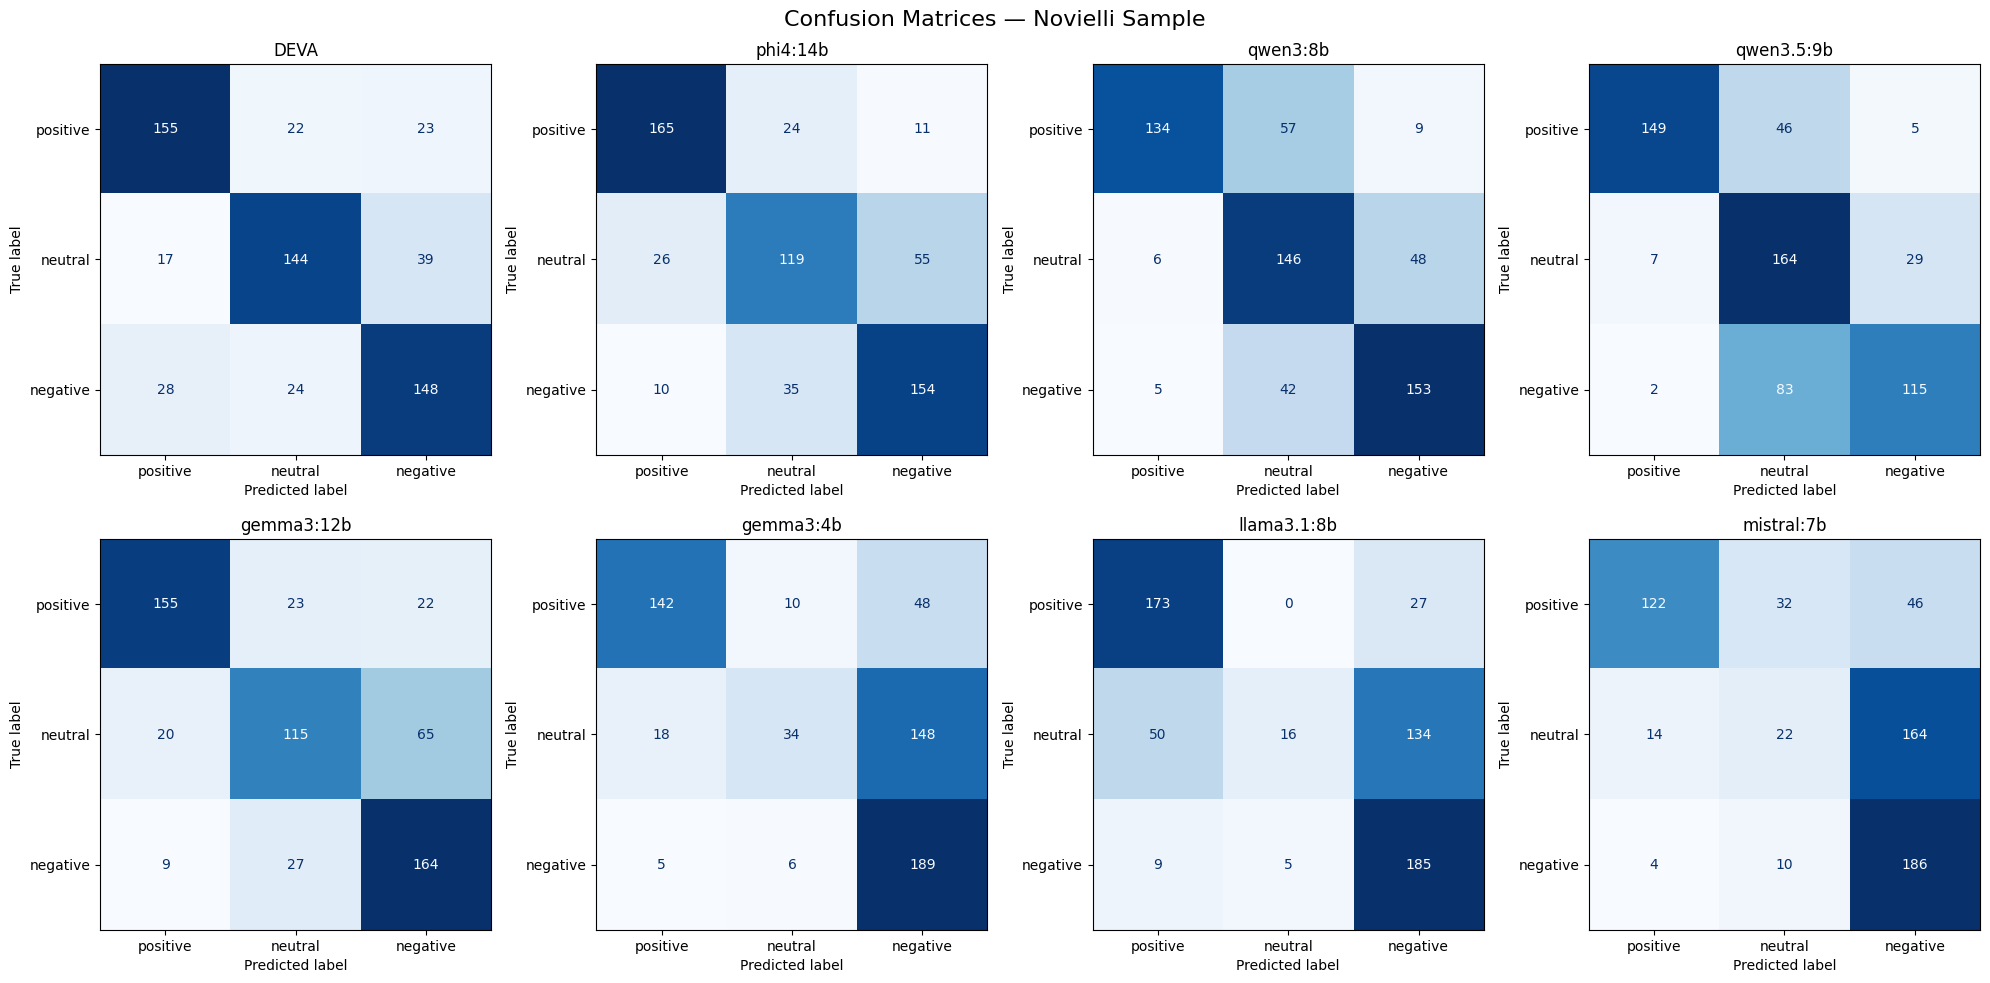

In [77]:
models = ['phi4:14b', 'qwen3:8b', 'qwen3.5:9b', 'gemma3:12b',
          'gemma3:4b', 'llama3.1:8b', 'mistral:7b']

fig, axes = plt.subplots(2, 4, figsize=(20, 10))
axes = axes.flatten()

cm = confusion_matrix(df_merged_nov_sample['polarity'],                                                                                         
                      df_merged_nov_sample['deva_polarity'], labels=labels)
disp = ConfusionMatrixDisplay(cm, display_labels=labels)                                                                                        
disp.plot(ax=axes[0], cmap='Blues', colorbar=False)
axes[0].set_title('DEVA')

for i, model in enumerate(models):
    cm = confusion_matrix(df_sample_nov['polarity'],
                          df_sample_nov[f'{model}_polarity'], labels=labels)
    disp = ConfusionMatrixDisplay(cm, display_labels=labels)
    disp.plot(ax=axes[i + 1], cmap='Blues', colorbar=False)
    axes[i + 1].set_title(model)

fig.suptitle('Confusion Matrices — Novielli Sample', fontsize=16)
plt.tight_layout()
fig.savefig('../output/confusion_matrices_novielli.png', dpi=150, bbox_inches='tight')                                                          
plt.show()


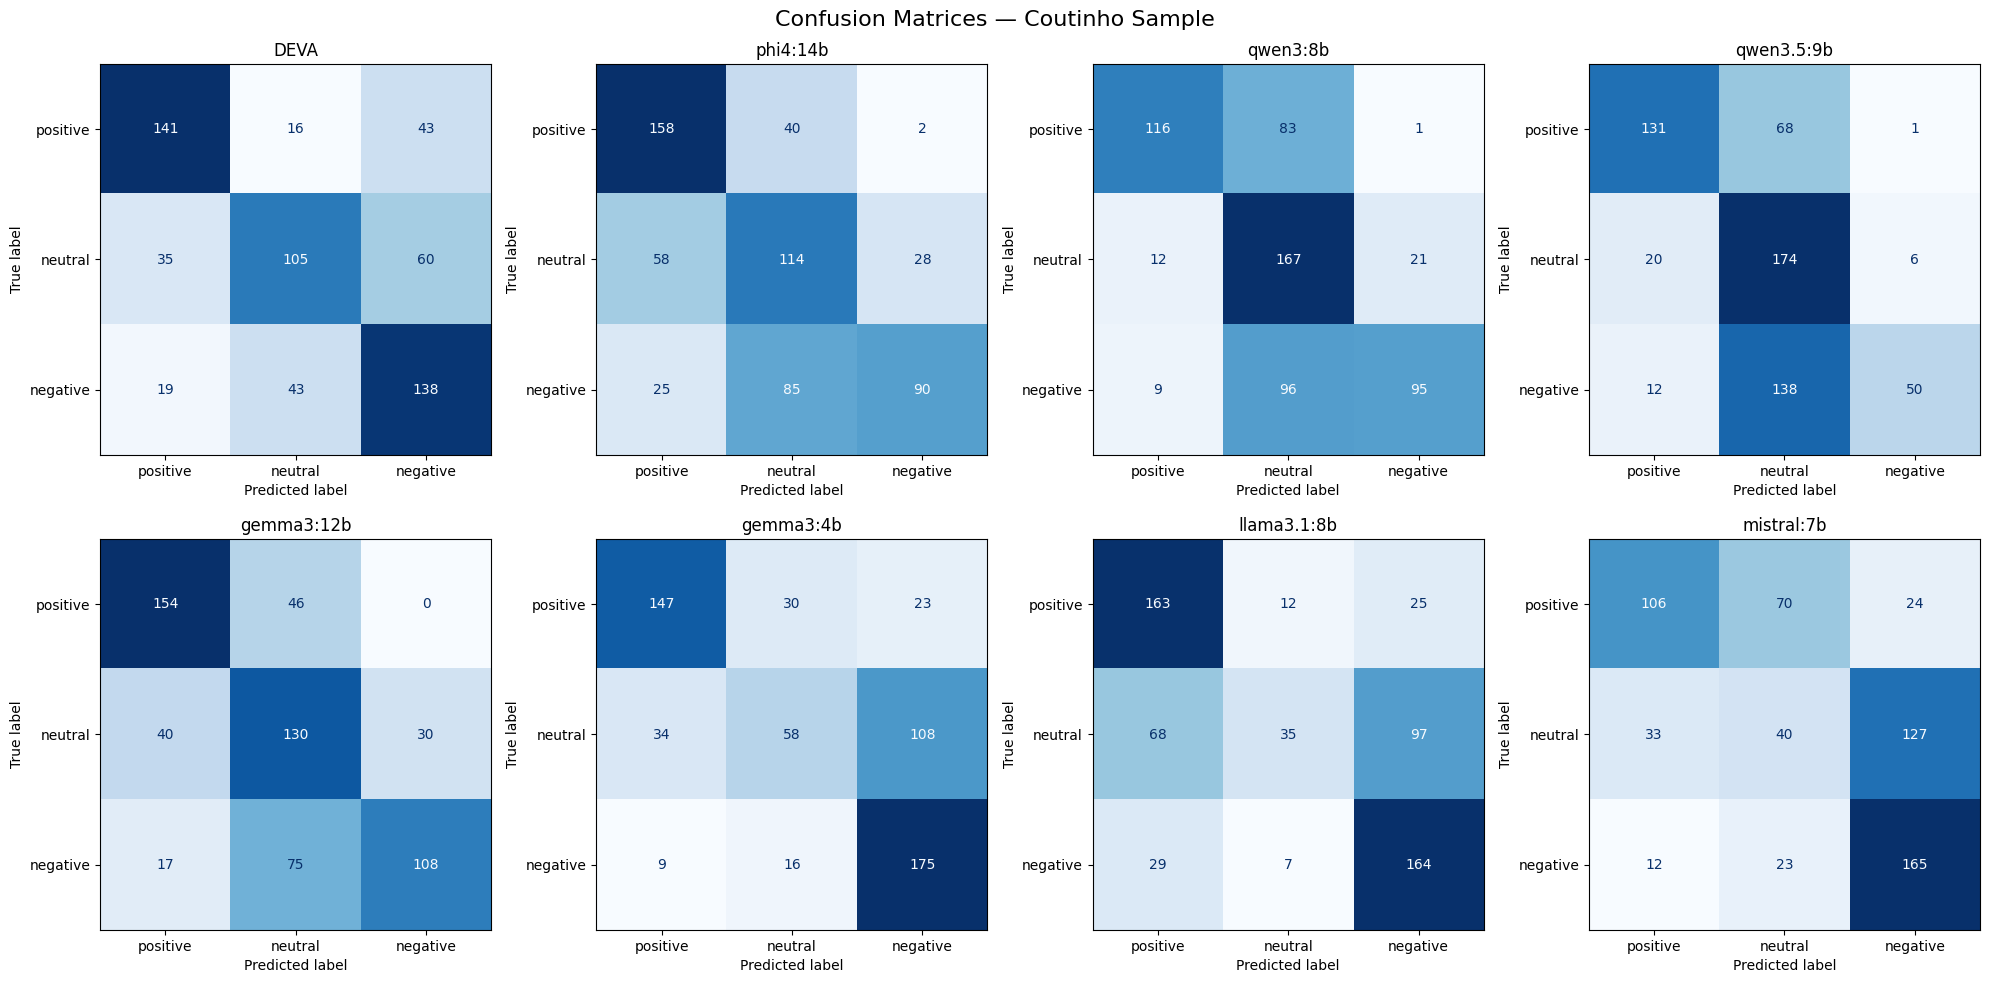

In [78]:
fig, axes = plt.subplots(2, 4, figsize=(20, 10))
axes = axes.flatten()

cm = confusion_matrix(df_merged_cou_sample['polarity'],                                                                                         
                      df_merged_cou_sample['deva_polarity'], labels=labels)
disp = ConfusionMatrixDisplay(cm, display_labels=labels)                                                                                        
disp.plot(ax=axes[0], cmap='Blues', colorbar=False)
axes[0].set_title('DEVA')

for i, model in enumerate(models):
    cm = confusion_matrix(df_sample_cou['polarity'],
                          df_sample_cou[f'{model}_polarity'], labels=labels)
    disp = ConfusionMatrixDisplay(cm, display_labels=labels)
    disp.plot(ax=axes[i + 1], cmap='Blues', colorbar=False)
    axes[i + 1].set_title(model)

fig.suptitle('Confusion Matrices — Coutinho Sample', fontsize=16)
plt.tight_layout()
fig.savefig('../output/confusion_matrices_coutinho.png', dpi=150, bbox_inches='tight')
plt.show()

Let's analyze Gemma3:12b, since it seems to be the best performing model:

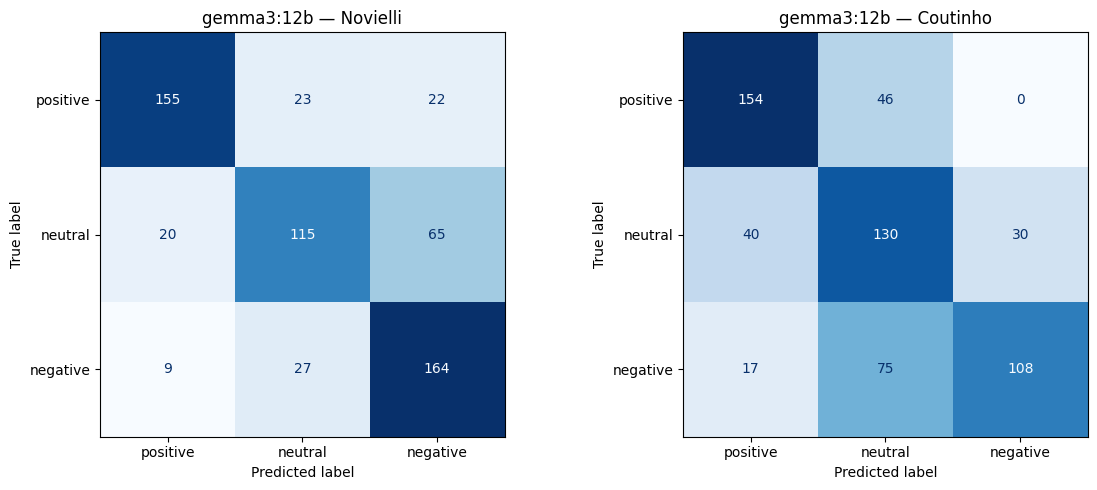

In [79]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))
                                                                                                                                                                             
# Novielli
cm = confusion_matrix(df_sample_nov['polarity'],                                                                                                                           
                     df_sample_nov['gemma3:12b_polarity'], labels=labels)                                                                                                 
ConfusionMatrixDisplay(cm, display_labels=labels).plot(ax=axes[0], cmap='Blues', colorbar=False)
axes[0].set_title('gemma3:12b — Novielli')                                                                                                                                 
                
# Coutinho                                                                                                                                                                 
cm = confusion_matrix(df_sample_cou['polarity'],
                      df_sample_cou['gemma3:12b_polarity'], labels=labels)                                                                                                 
ConfusionMatrixDisplay(cm, display_labels=labels).plot(ax=axes[1], cmap='Blues', colorbar=False)
axes[1].set_title('gemma3:12b — Coutinho')                                                                                                                                 
                
plt.tight_layout()                                                                                                                                                         
fig.savefig('../output/confusion_matrices_gemma3_12b.png', dpi=150, bbox_inches='tight')
plt.show() 

### 1. Error Analysis

In [80]:
# Novielli: neutral-negative misclassifications
nov_neutral_as_neg = df_sample_nov[
    (df_sample_nov['polarity'] == 'neutral') &
    (df_sample_nov['gemma3:12b_polarity'] == 'negative')
]['text']
print(f"Count: {len(nov_neutral_as_neg)}")
nov_neutral_as_neg.tolist()

Count: 65


['I consider the issues with views to be so widespread and severe that I am not real interested in installing tests for little bits of functionality; I only touched them to remove the obstacle to the Vector#isEmpty patch.',
 "Sounds reasonable, at least until another 'fix' is available (if ever).",
 "Don't move `head` around, the preferred layout is homepage, url, (version), sha1, newline, head, newline, devel block.  Remove the 1.7.1 version here, Homebrew can parse that one fine, and it triggers an `audit` warning otherwise.",
 'Could simple unset them in CommandTask::getShellList from listing. TBH that is hacky at best. Using reflection to check for a attribute marking it as hidden would slow it down considerably but could be a clean way to do it.',
 'This occurs when the Firewall redirects me on ``kernel.request`` as the request has not been added yet in the stack of the profiler.',
 'This breaks every formula which uses `gfortran`. See #15103.',
 'session.reset() is invalid in thi

In [81]:
# Coutinho: negative→neutral
cou_neg_as_neutral = df_sample_cou[                                                                                                                                        
    (df_sample_cou['polarity'] == 'negative') &
    (df_sample_cou['gemma3:12b_polarity'] == 'neutral')
]['clean_message']                                                                                                                                                                  
print(f"Count: {len(cou_neg_as_neutral)}")
cou_neg_as_neutral.tolist()       

Count: 75


["It's my fault, not the bot's. I got behind reviewing community PRs.  The bot doesn't check source issues for updates yet, although I plan to improve it at some point.",
 "The idea is that repackager may do other things than messing up with archive layout. In may populate manifest with custom SpringBoot metadata, for example. So you may not want to disable it completely. My understanding was that NONE layout is used in unit testing and has no real world application. Anyway, let's wait for what  has to say.",
 "We may need to do this internally, as we're not turning on deprecation on dagger1 internally, since it slows down the builds of really large projects (seriously - the extra i/o is a problem). So we have to do some fancy magic with MOE to do things differently between the two repos.  Let me consult a bit though.  We might yet use this pull. ",
 'sorry for the slow feedback, the PR should now be ready for review. I am wondering if some more test cases could be added, I will contin

In [82]:
# Coutinho: positive→neutral                                                                                                                                               
cou_pos_as_neutral = df_sample_cou[
    (df_sample_cou['polarity'] == 'positive') &                                                                                                                            
    (df_sample_cou['gemma3:12b_polarity'] == 'neutral')
]['clean_message']
print(f"Count: {len(cou_pos_as_neutral)}")                                                                                                                                 
cou_pos_as_neutral.tolist()

Count: 46


['Thanks for the PR!  In preparation for merging, would you please update your commit message to include the issue that you fixed as well? Something like:',
 'Oh, not really. I see your point and all that I can say is that maybe I was considering only my own use cases, where interruption is really a frequent thing, and I may have thought that this class was intended just for those situations. But thinking more carefully, it does not seem unlikely to use methods from this class, for example, just to avoid the verbosity of having to deal with InterruptedException in situations where the thread is actually never interrupted.',
 "Thanks, I don't think it's strictly necessary and having the value in a variable before returning helps sometimes while debugging, to set a breakpoint before returning. So, for now, I'll pass on this one. Maybe in a future, when I'm doing some benchmarks and trying to optimize the code I'll optimize some places like this, but for now, I think it's fine as it is, s

### 2. Text length analysis

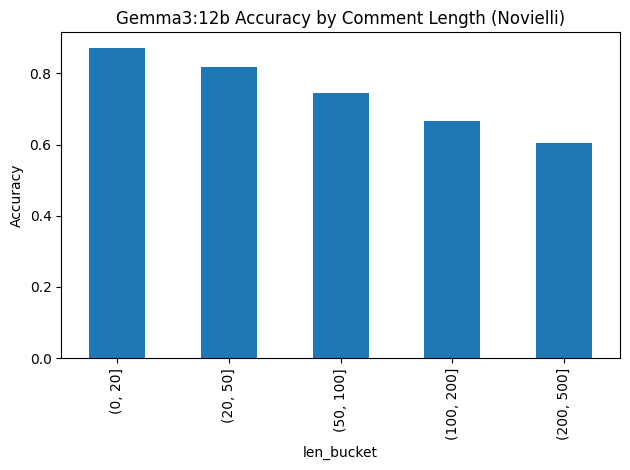

In [83]:
df_sample_nov['text_len'] = df_sample_nov['text'].str.len()
df_sample_nov['gemma_correct'] = df_sample_nov['polarity'] == df_sample_nov['gemma3:12b_polarity']                                                                         
                                                                                                                                                                           
# Error rate by length bucket                                                                                                                                              
df_sample_nov['len_bucket'] = pd.cut(df_sample_nov['text_len'], bins=[0, 20, 50, 100, 200, 500, 5000])                                                                     
error_by_len = df_sample_nov.groupby('len_bucket')['gemma_correct'].mean()                                                                                                 
error_by_len.plot(kind='bar', title='Gemma3:12b Accuracy by Comment Length (Novielli)')
plt.ylabel('Accuracy')                                                                                                                                                     
plt.tight_layout()                                                                                                                                                         
plt.show()             

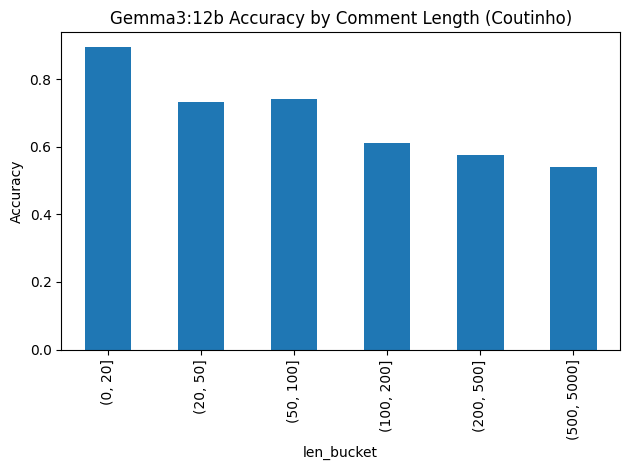

In [84]:
df_sample_cou['text_len'] = df_sample_cou['clean_message'].str.len()
df_sample_cou['gemma_correct'] = df_sample_cou['polarity'] == df_sample_cou['gemma3:12b_polarity']                                                                         
                                                                                                                                                                           
# Error rate by length bucket                                                                                                                                              
df_sample_cou['len_bucket'] = pd.cut(df_sample_cou['text_len'], bins=[0, 20, 50, 100, 200, 500, 5000])                                                                     
error_by_len = df_sample_cou.groupby('len_bucket')['gemma_correct'].mean()                                                                                                 
error_by_len.plot(kind='bar', title='Gemma3:12b Accuracy by Comment Length (Coutinho)')
plt.ylabel('Accuracy')                                                                                                                                                     
plt.tight_layout()                                                                                                                                                         
plt.show()             

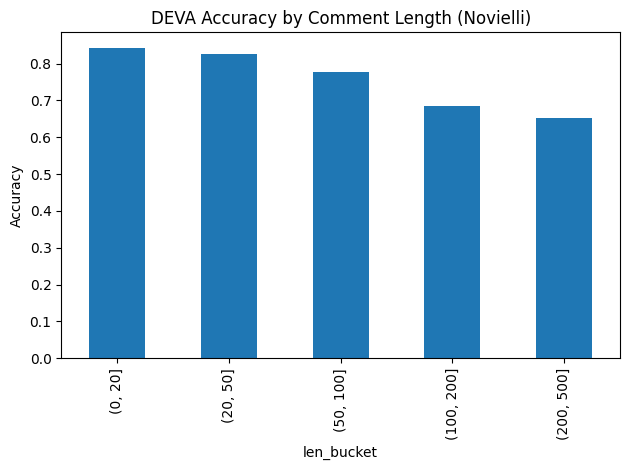

In [85]:
# DEVA
df_merged_nov_sample['text_len'] = df_merged_nov_sample['text'].str.len()                                                                                                  
df_merged_nov_sample['deva_correct'] = df_merged_nov_sample['polarity'] == df_merged_nov_sample['deva_polarity']                                                           
                                                                                                                                                                             
df_merged_nov_sample['len_bucket'] = pd.cut(df_merged_nov_sample['text_len'], bins=[0, 20, 50, 100, 200, 500, 5000])                                                       
error_by_len = df_merged_nov_sample.groupby('len_bucket')['deva_correct'].mean()
error_by_len.plot(kind='bar', title='DEVA Accuracy by Comment Length (Novielli)')                                                                                          
plt.ylabel('Accuracy')
plt.tight_layout()                                                                                                                                                         
plt.show()      

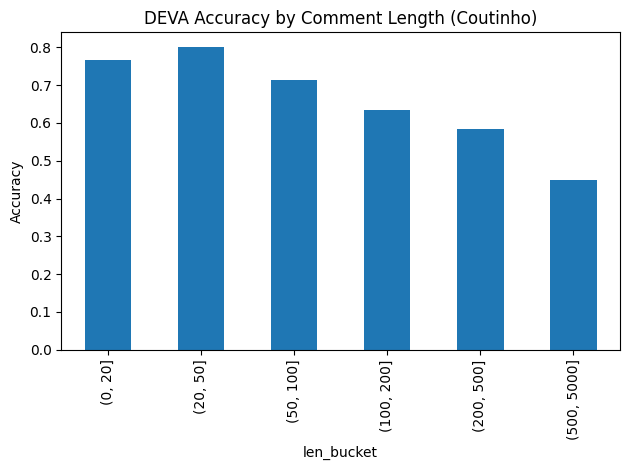

In [86]:
# DEVA
df_merged_cou_sample['text_len'] = df_merged_cou_sample['text'].str.len()                                                                                                  
df_merged_cou_sample['deva_correct'] = df_merged_cou_sample['polarity'] == df_merged_cou_sample['deva_polarity']                                                           
                                                                                                                                                                             
df_merged_cou_sample['len_bucket'] = pd.cut(df_merged_cou_sample['text_len'], bins=[0, 20, 50, 100, 200, 500, 5000])                                                       
error_by_len = df_merged_cou_sample.groupby('len_bucket')['deva_correct'].mean()
error_by_len.plot(kind='bar', title='DEVA Accuracy by Comment Length (Coutinho)')                                                                                          
plt.ylabel('Accuracy')
plt.tight_layout()                                                                                                                                                         
plt.show()      

### 3. Confusion pair heatmap with examples

In [87]:
def get_examples(df, true_label, pred_label, pred_col='gemma3:12b_polarity', n=3):
    """Get n example texts for a specific (true, predicted) pair."""                                                                                                       
    mask = (df['polarity'] == true_label) & (df[pred_col] == pred_label)                                                                                                   
    return df[mask]['text'].head(n).tolist()                                                                                                                               
                                                                                                                                                                             
# Build example table for all confusion pairs                                                                                                                              
for true_l in labels:                                                                                                                                                      
    for pred_l in labels:                                                                                                                                                  
        examples = get_examples(df_sample_nov, true_l, pred_l)
        if examples:
            print(f"\n{'='*60}")
            print(f"True: {true_l} → Predicted: {pred_l} ({len(examples)} shown)")
            print('='*60)                                                                                                                                                  
            for ex in examples:
                print(f"  • {ex}")   


True: positive → Predicted: positive (3 shown)
  • Yay nice fix.
  • You are right. Not sure why I added it there. Thanks for fixing.
  • lol that would work wouldn't it? :+1: 

True: positive → Predicted: neutral (3 shown)
  • That Commented out code should be removed, if not used :).
  • @AlexDenisov lol. I dont have command button :) Feel free to send PR
  • Tbh no idea, i don't have sniffs for these, just based myself off the sql comment blocks :P  [EDIT] Sems a bit more logical though.

True: positive → Predicted: negative (3 shown)
  • @jeresig - Welp sucko, when they fix it then something like a weak inference + version sniff will do. As for them not fixing bugs because it will affect a js lib; that is my new pet peeve, browsers should fix bugs and let libs fix there own bugs :P
  • Hackfix* :p Or workaround-fix \*pricking off\* 
  • @isaacs  ```js function Deflate(opts) {   if (!(this instanceof Deflate)) return new Deflate(opt);   Zlib.call(this, opts, binding.Deflate); } ```

### Novielli Test Set (testing)

In [88]:
test_ids = pd.read_csv('../output/novielli_test_ids.csv')['x'].astype(str).tolist()                                                             
df_novielli_test = df_novielli[df_novielli['id'].astype(str).isin(test_ids)] 
df_novielli_test

,id,polarity,text
11,2256549,neutral,"Because I thought I didn't need the quotes, wh..."
12,2190149,negative,"@gibson042, You're not gonna believe this but ..."
13,2080638,neutral,Yeah I agree that makes more sense. I can do a...
14,2049583,positive,Very deep ;-)
16,1569102,neutral,I don't agree with Ambal. The name of variable...
...,...,...,...
7102,3870846,positive,"I have no idea either, I just trust the spray ..."
7108,5675386,positive,The `as_json` requirement is a little looser t...
7114,1218482,negative,I would like this to not be in the API at all....
7115,20221,negative,This impl is weird. Uses system identityHashCo...


In [89]:
write_deva_input(df_novielli_test, DEVA_INPUT_DIR / "nov_gh_test.txt")

In [91]:
df_deva_novielli_test = parse_deva_output(DEVA_OUTPUT_DIR / "nov_gh_test.txt", "novielli_test")
df_deva_novielli_test.head(5)

,id,text,valence,arousal,deva_label,dataset
0,2256549,"Because I thought I didn't need the quotes, wh...",1,-2,NEUTRAL (LA),novielli_test
1,2190149,"@gibson042, You're not gonna believe this but ...",-3,-3,DEPRESSED,novielli_test
2,2080638,Yeah I agree that makes more sense. I can do a...,1,-3,EXCITED,novielli_test
3,2049583,Very deep ;-),1,2,NEUTRAL (HA),novielli_test
4,1569102,"""I don't agree with Ambal. The name of variabl...",1,-3,NEUTRAL (LA),novielli_test


In [92]:
df_deva_novielli_test['deva_polarity'] = df_deva_novielli_test['valence'].apply(valence_to_polarity)
df_deva_novielli_test

,id,text,valence,arousal,deva_label,dataset,deva_polarity
0,2256549,"Because I thought I didn't need the quotes, wh...",1,-2,NEUTRAL (LA),novielli_test,neutral
1,2190149,"@gibson042, You're not gonna believe this but ...",-3,-3,DEPRESSED,novielli_test,negative
2,2080638,Yeah I agree that makes more sense. I can do a...,1,-3,EXCITED,novielli_test,neutral
3,2049583,Very deep ;-),1,2,NEUTRAL (HA),novielli_test,neutral
4,1569102,"""I don't agree with Ambal. The name of variabl...",1,-3,NEUTRAL (LA),novielli_test,neutral
...,...,...,...,...,...,...,...
2130,3870846,"I have no idea either, I just trust the spray ...",-2,-2,DEPRESSED,novielli_test,negative
2131,5675386,The `as_json` requirement is a little looser t...,4,-3,RELAXED,novielli_test,positive
2132,1218482,I would like this to not be in the API at all....,-4,4,STRESSED,novielli_test,negative
2133,20221,This impl is weird. Uses system identityHashCo...,4,5,EXCITED,novielli_test,positive


In [93]:
df_nov_test_labels = df_novielli_test[['id', 'polarity']].copy()                                                                                
df_nov_test_labels['id'] = df_nov_test_labels['id'].astype(str)  

df_merged_nov_test = merge_with_gold(df_deva_novielli_test, df_nov_test_labels)                                                                 
metrics_deva_nov_test = compute_metrics(df_merged_nov_test, 'novielli_test (DEVA)')                                                             
metrics_deva_nov_test.round(3)      

,dataset,class,precision,recall,f1,support
0,novielli_test (DEVA),positive,0.695,0.735,0.715,603
1,novielli_test (DEVA),negative,0.647,0.735,0.688,626
2,novielli_test (DEVA),neutral,0.827,0.719,0.769,906
3,novielli_test (DEVA),macro avg,0.723,0.729,0.724,2135
4,novielli_test (DEVA),weighted avg,0.737,0.728,0.730,2135
5,novielli_test (DEVA),micro avg,0.728,0.728,0.728,2135


In [95]:
from sklearn.model_selection import train_test_split

df_train, df_test = train_test_split(
   df_novielli, test_size=0.30, stratify=df_novielli['polarity'], random_state=42                                                              
)                                                                                                                                               
print(f"Test set: {len(df_test)} rows")
print(df_test['polarity'].value_counts()) 

Test set: 2137 rows
polarity
neutral     907
negative    626
positive    604
Name: count, dtype: int64


In [96]:
write_deva_input(df_test, DEVA_INPUT_DIR / "nov_gh_test_2.txt")

In [99]:
df_deva_nov_test2 = parse_deva_output(DEVA_OUTPUT_DIR / "nov_gh_test_2.txt", "novielli_test2")
df_deva_nov_test2['deva_polarity'] = df_deva_nov_test2['valence'].apply(valence_to_polarity)                                                    
                                                                                                                                                
df_test_labels = df_test[['id', 'polarity']].copy()                                                                                             
df_test_labels['id'] = df_test_labels['id'].astype(str)                                                                                         
                                                                                                                                                
df_merged_nov_test2 = merge_with_gold(df_deva_nov_test2, df_test_labels)
metrics_deva_nov_test2 = compute_metrics(df_merged_nov_test2, 'novielli_test2 (DEVA)')
metrics_deva_nov_test2.round(3)            

,dataset,class,precision,recall,f1,support
0,novielli_test2 (DEVA),positive,0.708,0.750,0.728,604
1,novielli_test2 (DEVA),negative,0.646,0.703,0.673,626
2,novielli_test2 (DEVA),neutral,0.808,0.727,0.765,907
3,novielli_test2 (DEVA),macro avg,0.721,0.726,0.722,2137
4,novielli_test2 (DEVA),weighted avg,0.732,0.726,0.728,2137
5,novielli_test2 (DEVA),micro avg,0.726,0.726,0.726,2137


In [101]:
test_ids = pd.read_csv('../output/novielli_test_ids_sklearn150.csv')['ID'].astype(str).tolist()
df_novielli_test = df_novielli[df_novielli['id'].astype(str).isin(test_ids)]
write_deva_input(df_novielli_test, DEVA_INPUT_DIR / "nov_gh_test.txt")

In [102]:
df_deva_novielli_test = parse_deva_output(DEVA_OUTPUT_DIR / "nov_gh_test.txt", "novielli_test")
df_deva_novielli_test.head(5)

,id,text,valence,arousal,deva_label,dataset
0,3894703,Reverted.,1,1,NEUTRAL,novielli_test
1,2290082,These are the ones we currently hardcode in Te...,1,-3,NEUTRAL (LA),novielli_test
2,2256549,"Because I thought I didn't need the quotes, wh...",1,-2,NEUTRAL (LA),novielli_test
3,2025991,We can only compare our results to json.parse ...,1,-3,NEUTRAL (LA),novielli_test
4,1509152,"Yea, prepublish is what most people use in the...",3,-3,RELAXED,novielli_test


In [103]:
df_deva_novielli_test['deva_polarity'] = df_deva_novielli_test['valence'].apply(valence_to_polarity)
df_deva_novielli_test

,id,text,valence,arousal,deva_label,dataset,deva_polarity
0,3894703,Reverted.,1,1,NEUTRAL,novielli_test,neutral
1,2290082,These are the ones we currently hardcode in Te...,1,-3,NEUTRAL (LA),novielli_test,neutral
2,2256549,"Because I thought I didn't need the quotes, wh...",1,-2,NEUTRAL (LA),novielli_test,neutral
3,2025991,We can only compare our results to json.parse ...,1,-3,NEUTRAL (LA),novielli_test,neutral
4,1509152,"Yea, prepublish is what most people use in the...",3,-3,RELAXED,novielli_test,positive
...,...,...,...,...,...,...,...
2132,1526813,This code again! Will this hack never tire of ...,2,5,EXCITED,novielli_test,positive
2133,963856,"""Yeah, I'm capable of working around it. A se...",-3,-3,DEPRESSED,novielli_test,negative
2134,6359700,Formula updated to address this (would be nice...,1,-3,NEUTRAL (LA),novielli_test,neutral
2135,3832826,I trust you,-2,-2,DEPRESSED,novielli_test,negative


In [104]:
df_nov_test_labels = df_novielli_test[['id', 'polarity']].copy()                                                                                
df_nov_test_labels['id'] = df_nov_test_labels['id'].astype(str)  

df_merged_nov_test = merge_with_gold(df_deva_novielli_test, df_nov_test_labels)                                                                 
metrics_deva_nov_test = compute_metrics(df_merged_nov_test, 'novielli_test (DEVA)')                                                             
metrics_deva_nov_test.round(3)      

,dataset,class,precision,recall,f1,support
0,novielli_test (DEVA),positive,0.708,0.750,0.728,604
1,novielli_test (DEVA),negative,0.646,0.703,0.673,626
2,novielli_test (DEVA),neutral,0.808,0.727,0.765,907
3,novielli_test (DEVA),macro avg,0.721,0.726,0.722,2137
4,novielli_test (DEVA),weighted avg,0.732,0.726,0.728,2137
5,novielli_test (DEVA),micro avg,0.726,0.726,0.726,2137
